In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [2]:
# Load datasets

TRAIN_PATH = "train.csv"
TEST_PATH = "test.csv"

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)

print("\nTrain columns:")
print(train_df.columns.tolist())

Train shape: (31112, 16)
Test shape : (13334, 16)

Train columns:
['geological_era', 'weather_pattern', 'region', 'aptitude_score', 'performance_score', 'stability_index', 'personal_interest', 'load_ratio', 'brew_preference', 'instrument', 'species', 'index_weight', 'mineral_type', 'activity_duration', 'composite_rank', 'label']


In [3]:
# Missing value analysis

print("Missing values in TRAIN")
train_missing = train_df.isnull().sum()
print(train_missing[train_missing > 0])

print("\nMissing values in TEST")
test_missing = test_df.isnull().sum()
print(test_missing[test_missing > 0])

print("\nTotal missing values")
print("Train:", train_df.isnull().sum().sum())
print("Test :", test_df.isnull().sum().sum())

Missing values in TRAIN
geological_era       2
weather_pattern      3
region               4
aptitude_score       4
performance_score    2
stability_index      2
personal_interest    6
load_ratio           2
brew_preference      7
instrument           3
species              3
index_weight         3
mineral_type         3
activity_duration    2
composite_rank       1
label                3
dtype: int64

Missing values in TEST
geological_era       2
region               1
aptitude_score       1
stability_index      1
personal_interest    1
load_ratio           1
brew_preference      3
instrument           2
species              2
index_weight         1
activity_duration    1
composite_rank       4
label                1
dtype: int64

Total missing values
Train: 50
Test : 21


In [4]:
# Target distribution

print("TRAIN LABEL DISTRIBUTION")

print(train_df["label"].value_counts(dropna=False))

print(
    train_df["label"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

print("\nTEST LABEL DISTRIBUTION")

print(test_df["label"].value_counts(dropna=False))

print(
    test_df["label"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

TRAIN LABEL DISTRIBUTION
label
no     23645
yes     7464
NaN        3
Name: count, dtype: int64
label
no     76.00
yes    23.99
NaN     0.01
Name: proportion, dtype: float64

TEST LABEL DISTRIBUTION
label
no     10165
yes     3168
NaN        1
Name: count, dtype: int64
label
no     76.23
yes    23.76
NaN     0.01
Name: proportion, dtype: float64


In [5]:
# Identify feature types

TARGET = "label"

X_full = train_df.drop(columns=[TARGET])
y_full = train_df[TARGET]

numeric_features = X_full.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_full.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['aptitude_score', 'performance_score', 'stability_index', 'load_ratio', 'index_weight', 'activity_duration', 'composite_rank']

Categorical features:
['geological_era', 'weather_pattern', 'region', 'personal_interest', 'brew_preference', 'instrument', 'species', 'mineral_type']

Number of numerical features: 7
Number of categorical features: 8


In [6]:
# Remove rows with missing target

train_clean = train_df.dropna(subset=["label"]).copy()
test_clean = test_df.dropna(subset=["label"]).copy()

print("Original train size:", len(train_df))
print("Clean train size   :", len(train_clean))

print("\nOriginal test size :", len(test_df))
print("Clean test size    :", len(test_clean))

print("\nRemoved training rows:",
      len(train_df) - len(train_clean))

print("Removed test rows:",
      len(test_df) - len(test_clean))

Original train size: 31112
Clean train size   : 31109

Original test size : 13334
Clean test size    : 13333

Removed training rows: 3
Removed test rows: 1


In [7]:
# Separate X and y
# Encode target label
# no  -> 0
# yes -> 1

X = train_clean.drop(columns=["label"])

y = train_clean["label"].map({
    "no": 0,
    "yes": 1
})

X_test = test_clean.drop(columns=["label"])

y_test = test_clean["label"].map({
    "no": 0,
    "yes": 1
})

In [8]:
# Train / validation split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=17,
    stratify=y
)

print("Training set  :", X_train.shape)
print("Validation set:", X_val.shape)

print("\nTraining label distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation label distribution:")
print(y_val.value_counts(normalize=True))

Training set  : (24887, 15)
Validation set: (6222, 15)

Training label distribution:
label
0    0.760076
1    0.239924
Name: proportion, dtype: float64

Validation label distribution:
label
0    0.760045
1    0.239955
Name: proportion, dtype: float64


In [9]:
# Preprocessing pipelines

# Numerical preprocessing for Decision Tree
numeric_transformer_tree = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Categorical preprocessing for Decision Tree
categorical_transformer_tree = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

preprocessor_tree = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_tree, numeric_features),
        ("cat", categorical_transformer_tree, categorical_features)
    ]
)


# Numerical preprocessing for KNN
numeric_transformer_knn = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing for KNN
categorical_transformer_knn = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

preprocessor_knn = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_knn, numeric_features),
        ("cat", categorical_transformer_knn, categorical_features)
    ]
)

print("Preprocessing pipelines created.")

Preprocessing pipelines created.


In [10]:
# Decision Tree pipeline

dt_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_tree),
        ("classifier", DecisionTreeClassifier(
            random_state=8
        ))
    ]
)

print(dt_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['aptitude_score',
                                                   'performance_score',
                                                   'stability_index',
                                                   'load_ratio', 'index_weight',
                                                   'activity_duration',
                                                   'composite_rank']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                 

In [11]:
# Decision Tree hyperparameter tuning

dt_param_grid = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [5, 8, 10, 15, None],
    "classifier__min_samples_leaf": [1, 5, 10, 20]
}

dt_grid = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=dt_param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

dt_grid.fit(X_train, y_train)

print("\n===== BEST DECISION TREE =====")

print("Best parameters:")
print(dt_grid.best_params_)

print("\nBest validation F1:")
print(round(dt_grid.best_score_, 4))

Fitting 3 folds for each of 40 candidates, totalling 120 fits

===== BEST DECISION TREE =====
Best parameters:
{'classifier__criterion': 'gini', 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 20}

Best validation F1:
0.6133


In [12]:
# Best Decision Tree

best_dt = dt_grid.best_estimator_

print("Best Decision Tree:")
print(best_dt)

Best Decision Tree:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['aptitude_score',
                                                   'performance_score',
                                                   'stability_index',
                                                   'load_ratio', 'index_weight',
                                                   'activity_duration',
                                                   'composite_rank']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                             

In [13]:
# KNN pipeline

knn_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_knn),
        ("classifier", KNeighborsClassifier())
    ]
)

print(knn_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['aptitude_score',
                                                   'performance_score',
                                                   'stability_index',
                                                   'load_ratio', 'index_weight',
                                                   'activity_duration',
                                                   'composite_rank']),
                                                 ('cat',
                                                  Pipeline(steps=[('imput

In [14]:
# KNN hyperparameter tuning

knn_param_grid = {
    "classifier__n_neighbors": [5, 11, 21, 31, 51],
    "classifier__weights": ["uniform", "distance"],
    "classifier__p": [1, 2]
}

knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

knn_grid.fit(X_train, y_train)

print("\n===== BEST KNN =====")

print("Best parameters:")
print(knn_grid.best_params_)

print("\nBest validation F1:")
print(round(knn_grid.best_score_, 4))

Fitting 3 folds for each of 20 candidates, totalling 60 fits

===== BEST KNN =====
Best parameters:
{'classifier__n_neighbors': 31, 'classifier__p': 2, 'classifier__weights': 'distance'}

Best validation F1:
0.6327


In [15]:
# Best KNN

best_knn = knn_grid.best_estimator_

print("Best KNN:")
print(best_knn)

Best KNN:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['aptitude_score',
                                                   'performance_score',
                                                   'stability_index',
                                                   'load_ratio', 'index_weight',
                                                   'activity_duration',
                                                   'composite_rank']),
                                                 ('cat',
                                                  Pipeline(step

In [16]:
def evaluate_model(model, X_data, y_data, model_name):

    y_pred = model.predict(X_data)

    # Probability of yes
    y_prob = model.predict_proba(X_data)[:, 1]

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_data,
            y_pred
        ),
        "Precision": precision_score(
            y_data,
            y_pred,
            pos_label=1,
            zero_division=0
        ),
        "Recall": recall_score(
            y_data,
            y_pred,
            pos_label=1,
            zero_division=0
        ),
        "F1": f1_score(
            y_data,
            y_pred,
            pos_label=1,
            zero_division=0
        )
    }

    return results

In [17]:
dt_val_result = evaluate_model(
    best_dt,
    X_val,
    y_val,
    "Decision Tree"
)

knn_val_result = evaluate_model(
    best_knn,
    X_val,
    y_val,
    "KNN"
)

validation_results = pd.DataFrame(
    [dt_val_result, knn_val_result]
)

display(validation_results)

,Model,Accuracy,Precision,Recall,F1
0,Decision Tree,0.822404,0.693613,0.465506,0.557114
1,KNN,0.828672,0.668243,0.567984,0.614048


In [18]:
# Final evaluation on test set

dt_test_result = evaluate_model(
    best_dt,
    X_test,
    y_test,
    "Decision Tree"
)

knn_test_result = evaluate_model(
    best_knn,
    X_test,
    y_test,
    "KNN"
)

test_results = pd.DataFrame(
    [dt_test_result, knn_test_result]
)

display(
    test_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1
0,Decision Tree,0.8302,0.7055,0.4899,0.5782
1,KNN,0.8342,0.6695,0.5972,0.6313


In [19]:
# Detailed classification reports

dt_pred = best_dt.predict(X_test)
knn_pred = best_knn.predict(X_test)

print("DECISION TREE - CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        dt_pred,
        digits=4
    )
)

print("KNN - CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        knn_pred,
        digits=4
    )
)

DECISION TREE - CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.8548    0.9363    0.8937     10165
           1     0.7055    0.4899    0.5782      3168

    accuracy                         0.8302     13333
   macro avg     0.7802    0.7131    0.7360     13333
weighted avg     0.8193    0.8302    0.8187     13333

KNN - CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.8786    0.9081    0.8931     10165
           1     0.6695    0.5972    0.6313      3168

    accuracy                         0.8342     13333
   macro avg     0.7740    0.7527    0.7622     13333
weighted avg     0.8289    0.8342    0.8309     13333



Decision Tree Confusion Matrix:
[[9517  648]
 [1616 1552]]


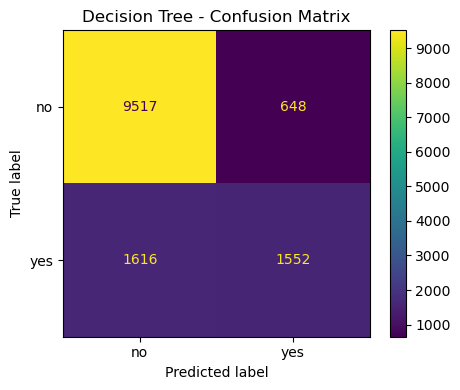

In [20]:
# Confusion Matrix - Decision Tree

cm_dt = confusion_matrix(
    y_test,
    dt_pred,
    labels=[0, 1]
)

print("Decision Tree Confusion Matrix:")
print(cm_dt)

fig, ax = plt.subplots(figsize=(5, 4))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["no", "yes"]
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title("Decision Tree - Confusion Matrix")

plt.tight_layout()
plt.show()

KNN Confusion Matrix:
[[9231  934]
 [1276 1892]]


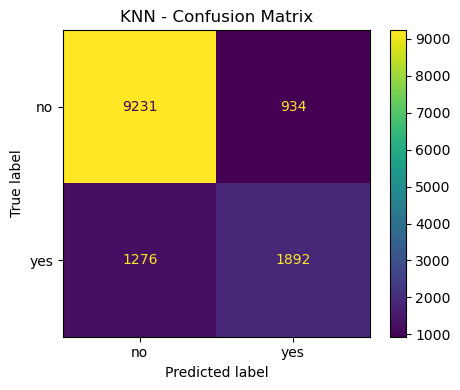

In [21]:
# Confusion Matrix - KNN

cm_knn = confusion_matrix(
    y_test,
    knn_pred,
    labels=[0,1]
)

print("KNN Confusion Matrix:")
print(cm_knn)

fig, ax = plt.subplots(figsize=(5, 4))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["no", "yes"]
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title("KNN - Confusion Matrix")

plt.tight_layout()
plt.show()